###Step 6: Statistical tests

1.   List item
1.   List item
2.   List item
2.   List item

- **Friedman test:** asks "do the models differ at all?" by ranking the models on every trace (rank 1 = lowest error) and checking whether some models are consistently ranked better than others. A small p-value (below 0.05) means yes.
- **Paired Wilcoxon signed-rank test:** compares **two** models (or strategies) on the same traces. It looks at the per-trace differences, not just the averages, so a few huge traces cannot decide the result alone.
- **Holm correction:** when many pairs are compared, some will look significant by luck. Holm corrects the p-values for this (`p_holm`). **Always use `p_holm`, not `p`.**
- **Metric:** per-trace **RMSE** (original units, lower is better). Never R² (some traces are almost flat). Ranks and paired differences do not need R².

**Columns in the tables** (reference = first model, candidate = second): `change_%` is the change in mean RMSE of the candidate compared with the reference (negative = candidate better); `cand_better` / `ref_better` / `tied` count traces; `effect` is the rank-biserial correlation (+1 = candidate better on every trace, −1 = reference better on every trace, 0 = no tendency).

**Three families of tests:** (1) Experiment 1: the models against each other, on all traces. (2) Experiment 2: retraining strategies, on the 20 traces used. (3) the ablation settings.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os, itertools, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
warnings.filterwarnings("ignore")

ROOT  = "/content/drive/MyDrive/dtn_project"
RES_A = f"{ROOT}/results"
RES_B = f"{ROOT}/results_b"
WINDOW = 12
DATASETS = ["5g", "4g", "operator"]
COLSET = {"5g": "single", "4g": "single", "operator": "value+daily"}
METRIC, ALPHA = "RMSE", 0.05

def tag(df):
    p = df.run_id.str.split("|")
    df["dataset"], df["colset"], df["window"], df["model"] = p.str[0], p.str[1], p.str[2], p.str[3]
    return df

def paired(ref, cand):
    """Paired Wilcoxon on per-trace errors. ref, cand: arrays over the same traces (lower = better)."""
    ref, cand = np.asarray(ref, float), np.asarray(cand, float); d = ref - cand      # d > 0: candidate better
    nz = d != 0
    out = dict(n=len(d), change_pct=100 * (cand.mean() - ref.mean()) / ref.mean(), cand_better=int((d > 0).sum()),
               ref_better=int((d < 0).sum()), tied=int((~nz).sum()), p=1.0, effect=0.0)
    if nz.sum() > 0:
        r = stats.rankdata(np.abs(d[nz])); wp, wm = r[d[nz] > 0].sum(), r[d[nz] < 0].sum()
        out["effect"] = (wp - wm) / (wp + wm)
        if nz.sum() >= 1:
            try: out["p"] = float(stats.wilcoxon(d[nz]).pvalue)
            except Exception: out["p"] = np.nan
    return out

def holm(df, col="p"):
    ok = df[col].notna()
    df["p_holm"] = np.nan
    if ok.sum(): df.loc[ok, "p_holm"] = multipletests(df.loc[ok, col], method="holm")[1]
    df["significant"] = df.p_holm < ALPHA
    return df

def friedman(M):
    """M: traces x methods matrix of errors. Returns p-value and average ranks (1 = best)."""
    try: p = float(stats.friedmanchisquare(*[M[:, j] for j in range(M.shape[1])]).pvalue)
    except Exception: p = np.nan
    return p, pd.Series(np.vstack([stats.rankdata(r) for r in M]).mean(0), index=M.columns if hasattr(M, "columns") else None)
print("helpers ready")

Mounted at /content/drive
helpers ready


## 2. Experiment 1: the models against each other
For each dataset: the 4 neural models, last value and ARIMA (and seasonal naive on operator), on **all traces** (79, 134, 55).
- **Friedman test** per dataset (are the models different at all?), and once over **all traces of all three datasets** together for the 6 models that exist everywhere (seasonal naive left out). That is the "separate traces act as separate test cases" idea from Phase 2.
- **Pairwise Wilcoxon with Holm** within each dataset (all pairs).

In [2]:
na = tag(pd.read_csv(f"{RES_A}/neural_trace_results.csv"))
na = na[(na.colset == na.dataset.map(COLSET)) & (na.window == f"w{WINDOW}")]
na = na.groupby(["dataset", "model", "trace"], as_index=False)[["MAE", "RMSE"]].mean()      # mean over seeds
nb = tag(pd.read_csv(f"{RES_B}/baseline_trace_results.csv")); ar = tag(pd.read_csv(f"{RES_B}/arima_trace_results.csv"))
E1 = pd.concat([na, nb[["dataset", "model", "trace", "MAE", "RMSE"]], ar[["dataset", "model", "trace", "MAE", "RMSE"]]])

fr_rows, pw_rows, ranks = [], [], {}
for ds in DATASETS:
    W = E1[E1.dataset == ds].pivot(index="trace", columns="model", values=METRIC).dropna()
    p, rk = friedman(W.values); rk.index = W.columns; ranks[ds] = rk
    fr_rows.append(dict(scope=ds, methods=W.shape[1], traces=len(W), friedman_p=p))
    for a, b in itertools.combinations(W.columns, 2):
        pw_rows.append(dict(dataset=ds, reference=a, candidate=b, **paired(W[a], W[b])))
Wall = E1[E1.model.isin(["lstm", "gru", "bilstm", "conv1d", "last_value", "arima"])].copy()
Wall["key"] = Wall.dataset + "|" + Wall.trace
Wp = Wall.pivot(index="key", columns="model", values=METRIC).dropna()
p, rk = friedman(Wp.values); rk.index = Wp.columns; ranks["all datasets"] = rk
fr_rows.append(dict(scope="all datasets (6 models)", methods=Wp.shape[1], traces=len(Wp), friedman_p=p))

FR = pd.DataFrame(fr_rows); PW = pd.concat([holm(g.copy()) for _, g in pd.DataFrame(pw_rows).groupby("dataset")])
FR.to_csv(f"{RES_B}/stats_exp1_friedman.csv", index=False); PW.to_csv(f"{RES_B}/stats_exp1_pairwise.csv", index=False)
pd.set_option("display.width", 220)
print("Friedman test (p < 0.05: the models are not all equal)"); print(FR.round(6).to_string(index=False))
print("\nAverage rank per model (1 = lowest error)"); print(pd.DataFrame(ranks).round(2).to_string())
show = ["dataset", "reference", "candidate", "change_pct", "cand_better", "ref_better", "tied", "effect", "p", "p_holm"]
print("\nPairs that stay significant after Holm (p_holm < 0.05):")
print(PW[PW.significant][show].round(4).to_string(index=False) if PW.significant.any() else "none")

Friedman test (p < 0.05: the models are not all equal)
                  scope  methods  traces  friedman_p
                     5g        6      79         0.0
                     4g        6     134         0.0
               operator        7      55         0.0
all datasets (6 models)        6     268         0.0

Average rank per model (1 = lowest error)
                  5g    4g  operator  all datasets
model                                             
arima           2.81  3.10      2.84          2.96
bilstm          2.85  3.74      3.44          3.41
conv1d          4.03  2.87      3.51          3.33
gru             3.61  2.96      3.44          3.25
last_value      5.06  5.04      3.87          4.81
lstm            2.65  3.28      4.05          3.24
seasonal_naive   NaN   NaN      6.85           NaN

Pairs that stay significant after Holm (p_holm < 0.05):
 dataset  reference      candidate  change_pct  cand_better  ref_better  tied  effect      p  p_holm
      4g      arima 

## 3. Plot: average ranks
Average rank of each model per dataset and over all traces (lower is better). It shows at a glance which models are consistently good, which is more robust than mean RMSE.


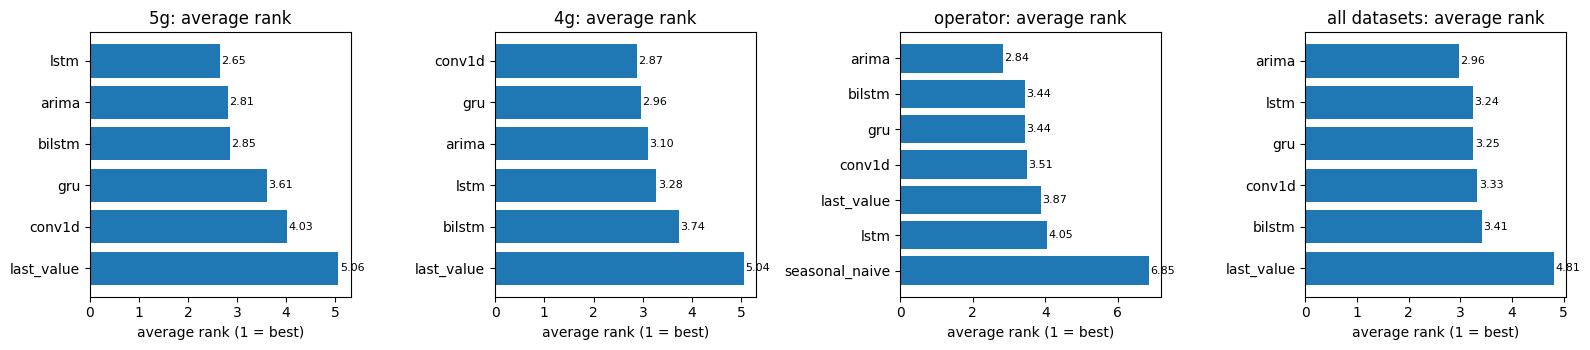

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (name, rk) in zip(axes, ranks.items()):
    rk = rk.sort_values(); ax.barh(rk.index, rk.values, color="C0"); ax.invert_yaxis()
    ax.set_title(f"{name}: average rank"); ax.set_xlabel("average rank (1 = best)")
    for y, v in enumerate(rk.values): ax.text(v + 0.03, y, f"{v:.2f}", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(f"{RES_B}/plot_stats_ranks.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Experiment 2: do the retraining strategies help?
For each dataset and model (20 traces): every strategy against `none`, and the key question "does the **drift detector** beat a fixed schedule with the same number of retrains?" (`kswin` vs `fixed_kswin`, `adwin` vs `fixed_adwin`). Holm is applied within each dataset and model. Where a strategy never retrained, its results equal `none` on that trace (a tie).


In [4]:
e2 = pd.read_csv(f"{RES_B}/exp2_trace_results.csv")
rows = []
for (ds, m), g in e2.groupby(["dataset", "model"]):
    W = g.pivot(index="trace", columns="strategy", values=METRIC).dropna()
    p, _ = friedman(W[["none", "adwin", "kswin", "fixed_adwin", "fixed_kswin"]].values)
    pairs = [("none", s) for s in ["adwin", "kswin", "fixed_adwin", "fixed_kswin"]] + [("fixed_kswin", "kswin"), ("fixed_adwin", "adwin")]
    fam = pd.DataFrame([dict(dataset=ds, model=m, reference=a, candidate=b, **paired(W[a], W[b])) for a, b in pairs])
    fam["friedman_p_5_strategies"] = p
    rows.append(holm(fam))
S2 = pd.concat(rows); S2.to_csv(f"{RES_B}/stats_exp2_pairwise.csv", index=False)
show = ["dataset", "model", "reference", "candidate", "change_pct", "cand_better", "ref_better", "tied", "effect", "p", "p_holm"]
print(S2[show].round(4).to_string(index=False))
print("\nSignificant after Holm:"); print(S2[S2.significant][show].round(4).to_string(index=False) if S2.significant.any() else "none")

 dataset  model   reference   candidate  change_pct  cand_better  ref_better  tied  effect      p  p_holm
      4g conv1d        none       adwin     -0.0482            1           0    19  1.0000 1.0000  1.0000
      4g conv1d        none       kswin      0.2121            7          10     3 -0.3464 0.2247  1.0000
      4g conv1d        none fixed_adwin      0.0000            0           0    20  0.0000 1.0000  1.0000
      4g conv1d        none fixed_kswin      0.1588            2           6    12 -0.5000 0.2500  1.0000
      4g conv1d fixed_kswin       kswin      0.0533            8           9     3 -0.1111 0.7119  1.0000
      4g conv1d fixed_adwin       adwin     -0.0482            1           0    19  1.0000 1.0000  1.0000
      4g    gru        none       adwin     -0.0450            1           0    19  1.0000 1.0000  1.0000
      4g    gru        none       kswin      0.1884            8           9     3 -0.1765 0.5477  1.0000
      4g    gru        none fixed_adwin      0

## 5. Ablations
For each dataset (best model, 20 traces): every setting against `none`, plus the two recent-window questions: is the **short** window or **all data** different from the **default** window (`kswin alpha=0.005`)? Holm within each dataset (12 comparisons).


In [5]:
ab = pd.read_csv(f"{RES_B}/ablation_trace_results.csv")
rows = []
for ds, g in ab.groupby("dataset"):
    W = g.pivot(index="trace", columns="config", values=METRIC).dropna()
    cfgs = [c for c in W.columns if c != "none"]
    pairs = [("none", c) for c in cfgs] + [("kswin alpha=0.005", "kswin recent=short"), ("kswin alpha=0.005", "kswin recent=all")]
    fam = pd.DataFrame([dict(dataset=ds, model=g.model.iloc[0], reference=a, candidate=b, **paired(W[a], W[b])) for a, b in pairs])
    rows.append(holm(fam))
S3 = pd.concat(rows); S3.to_csv(f"{RES_B}/stats_ablation_pairwise.csv", index=False)
print(S3[show].round(4).to_string(index=False))
print("\nSignificant after Holm:"); print(S3[S3.significant][show].round(4).to_string(index=False) if S3.significant.any() else "none")

 dataset model         reference          candidate  change_pct  cand_better  ref_better  tied  effect      p  p_holm
      4g   gru              none  adwin delta=0.002     -0.0450            1           0    19  1.0000 1.0000  1.0000
      4g   gru              none   adwin delta=0.01     -0.0450            1           0    19  1.0000 1.0000  1.0000
      4g   gru              none   adwin delta=0.05     -0.0251            1           1    18  0.3333 1.0000  1.0000
      4g   gru              none    adwin delta=0.2     -0.0282            4           1    15  0.4667 0.4375  1.0000
      4g   gru              none    adwin delta=0.5     -0.0746            4           2    14  0.5238 0.3125  1.0000
      4g   gru              none kswin alpha=0.0005     -0.0523            7           4     9  0.2424 0.5195  1.0000
      4g   gru              none  kswin alpha=0.005      0.1884            8           9     3 -0.1765 0.5477  1.0000
      4g   gru              none   kswin alpha=0.05     

In [6]:
rows = []
for ds in DATASETS:
    a = ar[ar.dataset == ds].set_index("trace").RMSE
    for m, g in e2[e2.dataset == ds].groupby("model"):
        for s in ["none", "kswin", "fixed_kswin"]:
            x = g[g.strategy == s].set_index("trace").RMSE; idx = x.index.intersection(a.index)
            rows.append(dict(dataset=ds, reference="arima", candidate=f"{m} / {s}", **paired(a[idx], x[idx])))
X = holm(pd.DataFrame(rows)); X.to_csv(f"{RES_B}/stats_retrained_vs_arima.csv", index=False)
print(X[["dataset", "candidate", "change_pct", "cand_better", "ref_better", "effect", "p", "p_holm"]].round(4).to_string(index=False))

 dataset            candidate  change_pct  cand_better  ref_better  effect      p  p_holm
      5g        bilstm / none     -8.2798            9          11  0.0667 0.8124     1.0
      5g       bilstm / kswin     -8.6438            9          11  0.1238 0.6477     1.0
      5g bilstm / fixed_kswin     -8.4024            9          11  0.0857 0.7562     1.0
      5g          lstm / none     -7.4191            9          11  0.1905 0.4749     1.0
      5g         lstm / kswin     -7.5076            9          11  0.2095 0.4304     1.0
      5g   lstm / fixed_kswin     -7.6095            9          11  0.2190 0.4091     1.0
      4g        conv1d / none     -0.7978           10          10  0.1524 0.5706     1.0
      4g       conv1d / kswin     -0.5873            9          11  0.1048 0.7012     1.0
      4g conv1d / fixed_kswin     -0.6403           10          10  0.0762 0.7841     1.0
      4g           gru / none     -0.3783            8          12  0.0571 0.8408     1.0
      4g  